# 01 · Análise exploratória

Tech Challenge Fase 3 · Alfabetização no Brasil

Antes de treinar qualquer modelo, queremos entender os dados. A pergunta que guia
este notebook é simples: o que dá para saber sobre um aluno antes da prova, e quanto
isso ajuda a prever se ele vai sair alfabetizado?

Usamos as tabelas da camada Gold da Fase 2 (alunos e indicador por município) e duas
fontes externas: o IBGE (Censo 2022 e PIB) e o Inep (Censo Escolar, Saeb e Inse).
No fim de cada seção anotamos o que aquilo muda na modelagem.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config as C
from src.data import carregar as L
from src.visualization import graficos as G

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
%matplotlib inline

In [2]:
alunos = L.carregar_alunos()
indicador = L.carregar_indicador_municipio()
ibge = L.carregar_ibge()

print(f"Alunos           : {len(alunos):>10,}  ({alunos['id_escola'].nunique():,} escolas, "
      f"{alunos['id_municipio'].nunique():,} municípios)")
print(f"Indicador munic. : {len(indicador):>10,}")
print(f"IBGE             : {len(ibge):>10,} municípios")

Alunos           :  3,867,999  (42,811 escolas, 5,548 municípios)
Indicador munic. :     23,995
IBGE             :      5,570 municípios


## 1. A base de alunos

In [3]:
resumo = alunos.groupby(["ano", "rede_nome"], observed=True).agg(
    alunos=("id_aluno", "size"),
    avaliados=("avaliado", "sum"),
    escolas=("id_escola", "nunique"),
)
resumo["participacao_%"] = 100 * resumo["avaliados"] / resumo["alunos"]
resumo

alunos  avaliados  escolas  participacao_%
ano  rede_nome                                             
2023 Estadual    155140     131522     3942           84.78
     Municipal  1592299    1371287    32834           86.12
2024 Estadual    280258     241074     5431           86.02
     Municipal  1840277    1610754    37065           87.53
     Privada         25         24        1           96.00

In [4]:
nulos = alunos.isna().mean().mul(100).round(2)
print("Percentual de nulos por coluna:")
print(nulos[nulos > 0].to_string())
print("\nNulos de proficiência entre os avaliados:",
      alunos.loc[alunos["avaliado"], "proficiencia_portugues"].isna().sum())
print("Duplicatas no grão (ano, id_aluno):", alunos.duplicated(["ano", "id_aluno"]).sum())

Percentual de nulos por coluna:
proficiencia_portugues   13.27
nome_municipio            0.01
sigla_uf                  0.01
nome_regiao               0.01
nome_mesorregiao          0.01

Nulos de proficiência entre os avaliados: 0


Duplicatas no grão (ano, id_aluno): 0


A base está limpa. Os únicos nulos de proficiência são dos alunos que não fizeram a
prova, e não há aluno repetido. A rede privada tem só 25 alunos e fica de fora, já
que o foco é a rede pública.

Como só existe resultado para quem fez a prova, o modelo é treinado com os alunos
avaliados.

## 2. O que estamos prevendo

In [5]:
publica = alunos[alunos["avaliado"] & alunos["rede"].isin([C.REDE_ESTADUAL, C.REDE_MUNICIPAL])]

def taxa(df):
    return 100 * np.average(df["alfabetizado"].astype(float), weights=df["peso_aluno"])

taxas = publica.groupby(["ano", "rede_nome"], observed=True).apply(taxa).unstack()
print("Taxa de alfabetização ponderada (%):")
taxas

Taxa de alfabetização ponderada (%):


rede_nome,Estadual,Municipal
ano,,
2023,60.09,57.21
2024,61.65,58.82


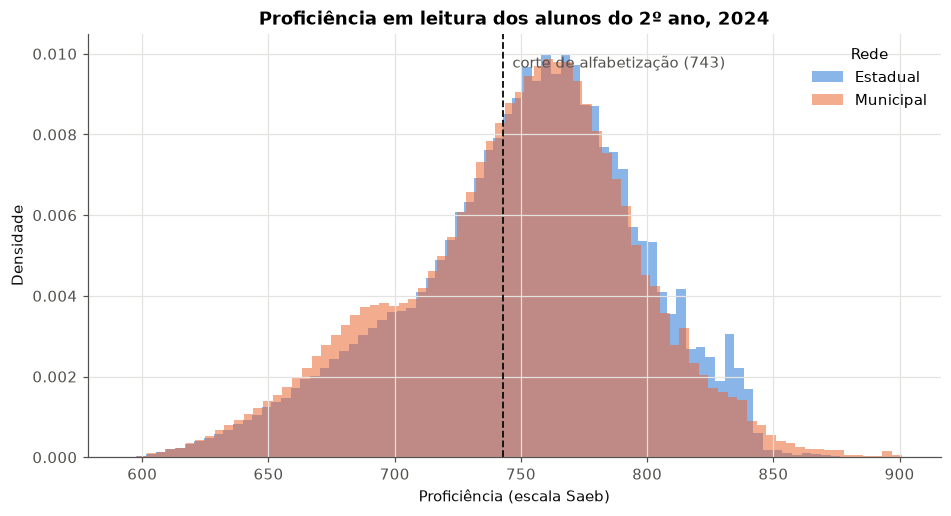

In [6]:
G.distribuicao_proficiencia(publica, C.ANO_ALVO);

In [7]:
corte = publica[publica["ano"] == C.ANO_ALVO]
consistente = ((corte["proficiencia_portugues"] >= C.PONTO_CORTE_SAEB) == corte["alfabetizado"]).mean()
perto = corte["proficiencia_portugues"].between(C.PONTO_CORTE_SAEB - 25, C.PONTO_CORTE_SAEB + 25).mean()
print(f"Alvo coerente com a regra dos 743 pontos: {consistente:.2%}")
print(f"Alunos a menos de 25 pontos do corte    : {perto:.1%}")

Alvo coerente com a regra dos 743 pontos: 100.00%
Alunos a menos de 25 pontos do corte    : 39.9%


Um aluno é considerado alfabetizado quando tira 743 pontos ou mais na prova de leitura.
Em 2024, cerca de 41% não chegaram lá. As duas classes têm tamanho parecido, então
não precisamos balancear nada.

Um cuidado importante: como o rótulo sai direto da nota, a nota do próprio ano não
pode entrar no modelo. Seria como dar a resposta da prova. Deixamos essa coluna (e
outras parecidas) numa lista de bloqueio em `src/config.py`, e um teste automático
confere isso.

Outro ponto: 4 em cada 10 alunos ficaram a menos de 25 pontos do corte. Para eles, a
diferença entre alfabetizado e não alfabetizado é pequena, e qualquer modelo vai errar
parte desses casos.

## 3. De onde vem a diferença entre os alunos?

Antes de escolher variáveis, vale saber quanto da diferença entre alunos se explica
pela UF, pelo município ou pela escola. Para isso calculamos o η²: quanto da variação
do resultado é explicada pela média de cada grupo.

In [8]:
alvo_2024 = corte.assign(y=corte["alfabetizado"].astype(float))
variancia = alvo_2024["y"].var()
eta = {nivel: alvo_2024.groupby(nivel, observed=True)["y"].transform("mean").var() / variancia
       for nivel in ["sigla_uf", "nome_mesorregiao", "id_municipio", "id_escola"]}
eta = pd.Series(eta, name="η²").rename(index={"sigla_uf": "UF", "nome_mesorregiao": "Mesorregião",
                                              "id_municipio": "Município", "id_escola": "Escola"})
eta.to_frame().style.format("{:.1%}")

,η²
UF,5.4%
Mesorregião,6.2%
Município,9.6%
Escola,16.8%


Esse foi o resultado que mais mudou nossa expectativa. Mesmo sabendo a escola exata
de cada aluno, só uns 17% da diferença entre eles fica explicada. O resto acontece
dentro da mesma turma e depende de coisas que não estão nos dados: família, frequência,
professor, o ritmo de cada criança.

Na prática, o modelo vai estimar o risco de um aluno daquela escola e daquele
município, mas não vai conseguir separar bem dois alunos da mesma sala. Por isso as
métricas por aluno vão ser modestas, e o resultado mais útil vai aparecer quando
juntarmos os alunos por município.

## 4. O passado ajuda a prever o futuro?

In [9]:
# O código da escola é o mesmo nos dois anos? Se for, a escola tem que estar no mesmo
# município em 2023 e em 2024.
escola_mun = alunos.drop_duplicates(["id_escola", "ano"]).pivot(
    index="id_escola", columns="ano", values="id_municipio").dropna()
mesmo_mun = (escola_mun[C.ANO_BASE] == escola_mun[C.ANO_ALVO]).mean()
mun_por_escola = alunos.groupby(["ano", "id_escola"])["id_municipio"].nunique()
print(f"Códigos de escola presentes nos dois anos         : {len(escola_mun):,}")
print(f"... no mesmo município nos dois anos              : {mesmo_mun:.1%}")
print(f"Escolas com mais de um município dentro do mesmo ano: {(mun_por_escola > 1).sum()}")

mun = indicador[indicador["rede"] == C.REDE_MUNICIPAL].pivot_table(
    index="id_municipio", columns="ano", values="taxa_alfabetizacao")
r_mun = mun[C.ANO_BASE].corr(mun[C.ANO_ALVO])
print(f"Correlação 2023 × 2024, municípios (rede municipal): {r_mun:.2f}")

Códigos de escola presentes nos dois anos         : 36,462
... no mesmo município nos dois anos              : 2.4%
Escolas com mais de um município dentro do mesmo ano: 0
Correlação 2023 × 2024, municípios (rede municipal): 0.64


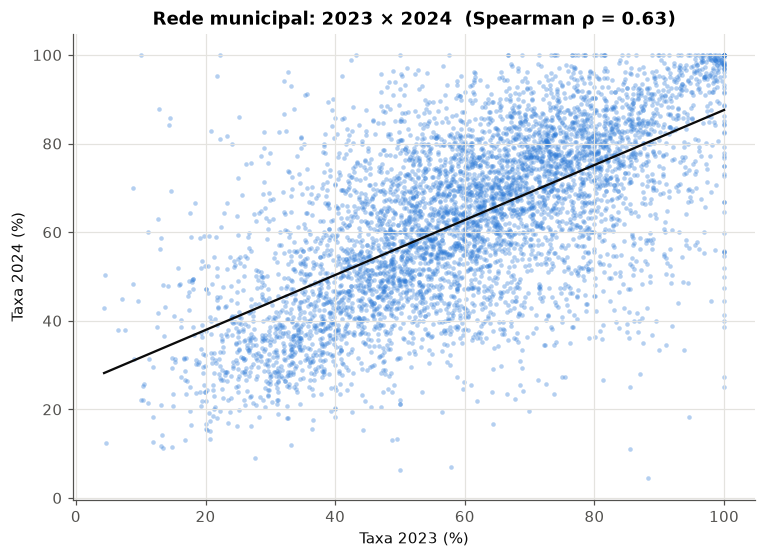

In [10]:
mun_plot = mun.dropna().rename(columns={C.ANO_BASE: "taxa_2023", C.ANO_ALVO: "taxa_2024"})
G.dispersao_relacao(mun_plot, "taxa_2023", "taxa_2024", "Rede municipal: 2023 × 2024",
                    "eda_persistencia_municipio", "Taxa 2023 (%)", "Taxa 2024 (%)");

In [11]:
mun_plot["variacao"] = mun_plot["taxa_2024"] - mun_plot["taxa_2023"]
mun_plot["quintil_2023"] = pd.qcut(mun_plot["taxa_2023"], 5, labels=["Q1 (pior)", "Q2", "Q3", "Q4", "Q5 (melhor)"])
mun_plot.groupby("quintil_2023", observed=True)["variacao"].describe()[["count", "mean", "50%"]]

,count,mean,50%
quintil_2023,,,
Q1 (pior),"1,080.00",11.86,8.69
Q2,"1,079.00",8.12,6.61
Q3,"1,079.00",3.07,3.48
Q4,"1,079.00",-0.61,1.36
Q5 (melhor),"1,079.00",-9.09,-4.74


No município, sim: o resultado de 2023 acompanha bem o de 2024 (correlação de 0,64).

Na escola, não dá para medir. Primeiro pensamos em usar o resultado de cada escola em
2023, mas a conferência acima mostrou que o código fictício da escola é sorteado de
novo a cada ano: quase nenhum código fica no mesmo município de um ano para o outro.
Dentro do mesmo ano, o código é consistente (nenhuma escola aparece em dois
municípios), então dá para usar a escola dentro do ano, mas não ligar a escola de 2024
à de 2023. Por isso o modelo não tem histórico de escola.

Também aparece uma regressão à média forte: os municípios que estavam pior em 2023
subiram em média 12 pontos percentuais, e os que estavam melhor caíram 9. Então não
basta repetir o ano anterior; o modelo precisa aprender esse movimento.

O que levamos para o modelo:
- o histórico do município (por rede) e da UF em 2023 entram como variáveis;
- da escola, entra só o tamanho em 2024 (número de matriculados), que é do próprio ano
  e é conhecido antes da prova.

## 5. Diferenças entre estados

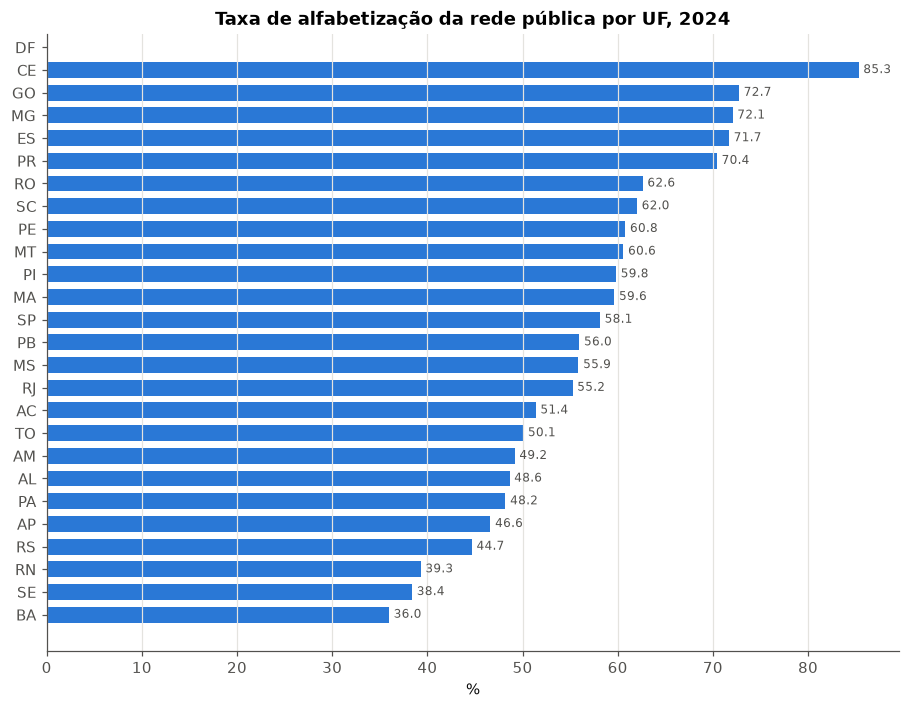

In [12]:
uf_2024 = (indicador[(indicador["ano"] == C.ANO_ALVO) & (indicador["rede"] == C.REDE_PUBLICA)]
           .groupby("sigla_uf")["taxa_uf"].first().reset_index())
G.taxa_por_categoria(uf_2024, "sigla_uf", "taxa_uf",
                     f"Taxa de alfabetização da rede pública por UF, {C.ANO_ALVO}",
                     "eda_taxa_por_uf");

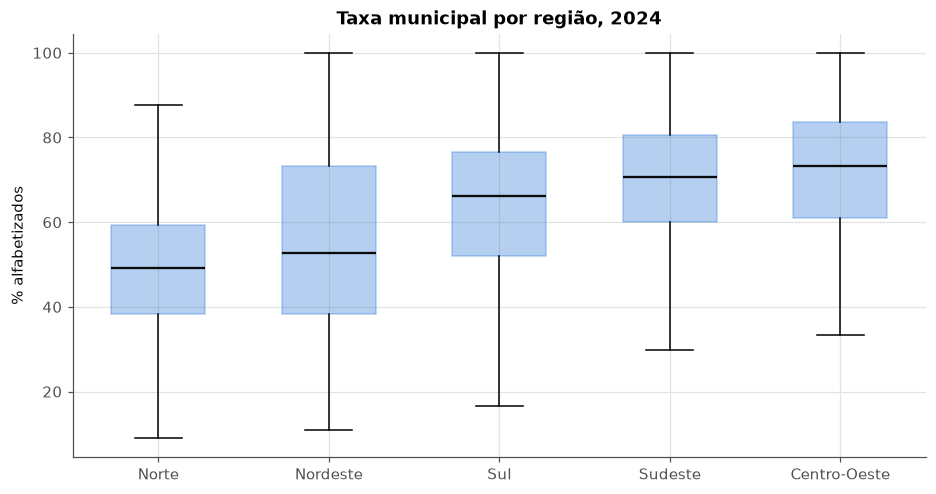

In [13]:
municipal_2024 = indicador[(indicador["ano"] == C.ANO_ALVO) & (indicador["rede"] == C.REDE_MUNICIPAL)]
G.boxplot_por_grupo(municipal_2024, "taxa_alfabetizacao", "nome_regiao",
                    f"Taxa municipal por região, {C.ANO_ALVO}", "eda_taxa_por_regiao", "% alfabetizados");

In [14]:
variacao_uf = (indicador[indicador["rede"] == C.REDE_PUBLICA]
               .groupby(["sigla_uf", "ano"])["taxa_uf"].first().unstack())
variacao_uf["variacao_pp"] = variacao_uf[C.ANO_ALVO] - variacao_uf[C.ANO_BASE]
variacao_uf.sort_values("variacao_pp").head(5)

ano,2023,2024,variacao_pp
sigla_uf,,,
RS,63.43,44.67,-18.76
AM,52.20,49.17,-3.03
PR,73.12,70.42,-2.70
RO,64.60,62.62,-1.98
BA,36.78,35.96,-0.82


A diferença entre estados é grande. O Ceará passa de 85%, enquanto Sergipe e Bahia
ficam abaixo de 40% na rede municipal. E dentro de cada região também há muita
variação.

O Rio Grande do Sul chama atenção: caiu quase 19 pontos de 2023 para 2024, enquanto o
resto do país subiu. Na Fase 2 já tínhamos marcado isso como possível mudança de
metodologia. Outra explicação possível são as enchentes de maio de 2024, que fecharam
escolas no estado. De qualquer forma, o modelo deve errar mais por lá.

UF e região entram no modelo como categorias. A mesorregião tem umas 140 categorias,
então em vez de criar uma coluna para cada uma, trocamos o nome pela taxa média da
mesorregião (target encoding), calculada sem olhar a própria linha.

## 6. Renda e contexto do município (IBGE)

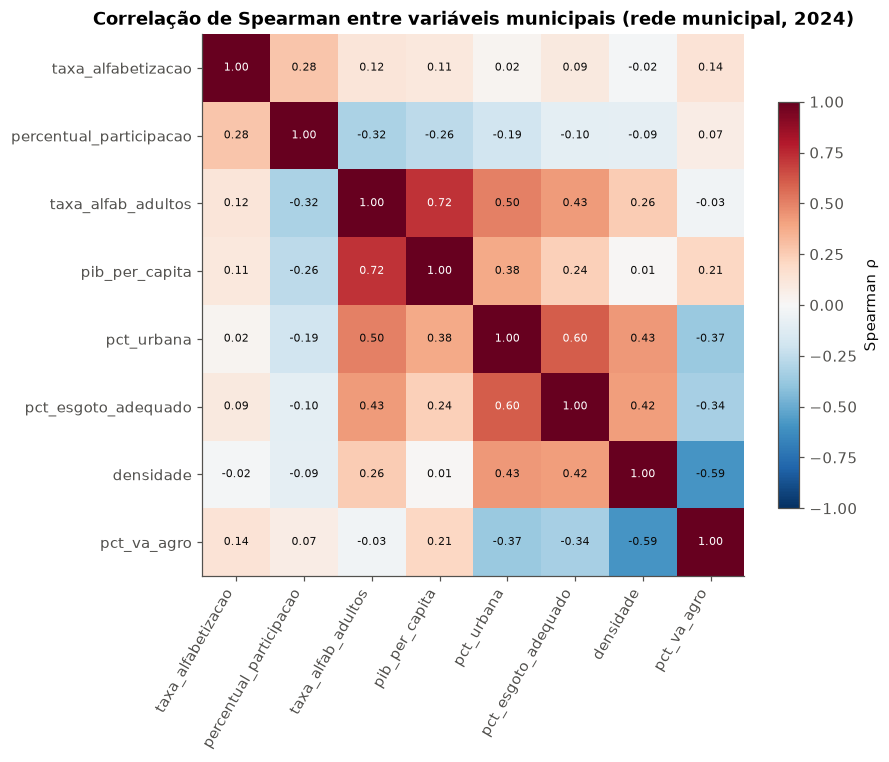

In [15]:
socio = municipal_2024.merge(ibge, on="id_municipio")
variaveis = ["taxa_alfabetizacao", "percentual_participacao", "taxa_alfab_adultos",
             "pib_per_capita", "pct_urbana", "pct_esgoto_adequado", "densidade", "pct_va_agro"]
G.matriz_correlacao(socio, variaveis, "eda_correlacao_socioeconomico",
                    "Correlação de Spearman entre variáveis municipais (rede municipal, 2024)");

In [16]:
por_regiao = {}
for regiao, parte in socio.groupby("nome_regiao"):
    por_regiao[regiao] = parte[["taxa_alfabetizacao", "taxa_alfab_adultos", "pib_per_capita",
                                "percentual_participacao"]].corr(method="spearman").iloc[0, 1:]
por_regiao = pd.DataFrame(por_regiao).T
por_regiao.loc["Brasil"] = socio[["taxa_alfabetizacao", "taxa_alfab_adultos", "pib_per_capita",
                                  "percentual_participacao"]].corr(method="spearman").iloc[0, 1:]
por_regiao.round(2)

,taxa_alfab_adultos,pib_per_capita,percentual_participacao
Centro-Oeste,-0.24,-0.16,0.41
Nordeste,-0.15,-0.13,0.49
Norte,0.21,0.24,0.29
Sudeste,-0.26,-0.18,0.29
Sul,-0.22,-0.09,0.15
Brasil,0.12,0.11,0.28


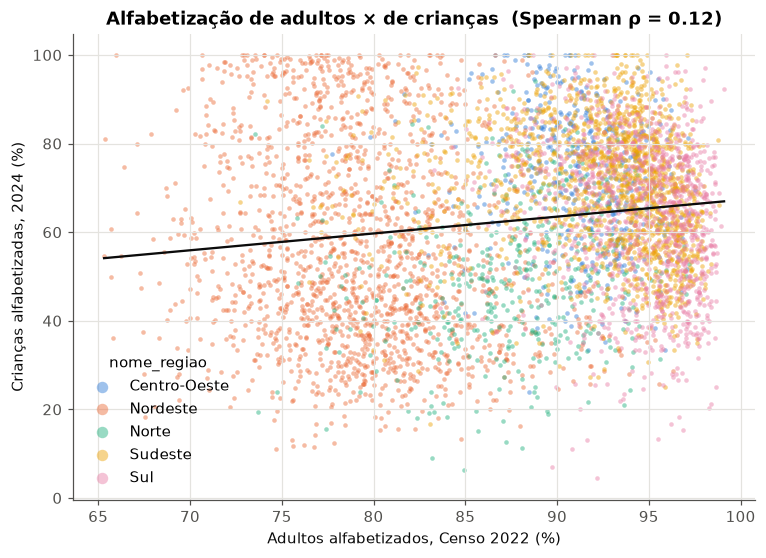

In [17]:
G.dispersao_relacao(socio, "taxa_alfab_adultos", "taxa_alfabetizacao",
                    "Alfabetização de adultos × de crianças", "eda_adultos_vs_criancas",
                    "Adultos alfabetizados, Censo 2022 (%)", "Crianças alfabetizadas, 2024 (%)",
                    cor_por="nome_regiao");

Esse resultado nos surpreendeu. A gente esperava que municípios mais ricos e com
mais adultos alfabetizados alfabetizassem mais crianças. No Brasil como um todo, a
relação é quase nula. E dentro de cada região, com exceção do Norte, ela chega a ser
negativa.

O gráfico ajuda a entender: o Nordeste tem os adultos menos alfabetizados do país, mas
tem municípios entre os melhores (Ceará) e entre os piores (Sergipe, Bahia) em
alfabetização infantil.

O que mais acompanha o resultado é a participação dos alunos na prova. Rede que
mobiliza os alunos para a avaliação costuma ser uma rede mais organizada.

A nossa leitura é que a política da rede e do estado pesa mais que a renda. O Ceará,
com o programa de alfabetização feito em parceria com os municípios, é o exemplo
mais conhecido. Isso não prova causa, mas orienta o modelo e as recomendações.

Mesmo assim, as variáveis do IBGE entram no modelo. Depois a análise de importância
(SHAP) vai mostrar quanto elas realmente pesam.

## 7. Dados das escolas (Inep)

Como não temos o histórico das escolas na base de alunos, buscamos informação sobre
elas em outros dados do Inep publicados antes de 2024:

- Saeb do 5º ano por escola (2019, 2021 e 2023), com turmas maiores que as do 2º ano;
- Inse 2023, o nível socioeconômico dos alunos de cada escola;
- Censo Escolar 2023, com infraestrutura, tempo integral e alunos por turma.

Os arquivos são baixados com `python -m src.data.externos_inep --baixar`.

In [18]:
escolas = L.carregar_censo_escolar()
print(f"Escolas com anos iniciais no Censo 2023: {len(escolas):,}")
ids_alunos = alunos["id_escola"].dropna().astype("int64")
print(f"Código de escola nos microdados de aluno: {ids_alunos.min():,} a {ids_alunos.max():,} "
      f"({ids_alunos.nunique():,} escolas)")
print(f"Código de escola no Censo Escolar       : {escolas['id_escola'].min():,} a {escolas['id_escola'].max():,}")
print(f"Códigos em comum                        : {len(set(ids_alunos) & set(escolas['id_escola'])):,}")

Escolas com anos iniciais no Censo 2023: 103,785
Código de escola nos microdados de aluno: 60,000,001 a 60,042,811 (42,811 escolas)
Código de escola no Censo Escolar       : 11,000,023 a 53,085,000


Códigos em comum                        : 0


Aqui tivemos um problema: os códigos de escola da base de alunos não batem com nenhum
código do Censo. Eles vão de 60000001 em diante, em sequência. O Inep troca o código
real da escola por um código fictício nessa base, para proteger os dados das
crianças.

Daria para tentar descobrir qual escola é qual cruzando município e número de alunos,
mas isso seria passar por cima de uma proteção feita de propósito, então não fizemos.
A saída foi juntar os dados das escolas por município e rede: por exemplo, a nota média
do 5º ano das escolas municipais de cada cidade. Essas variáveis começam com `inep_`.

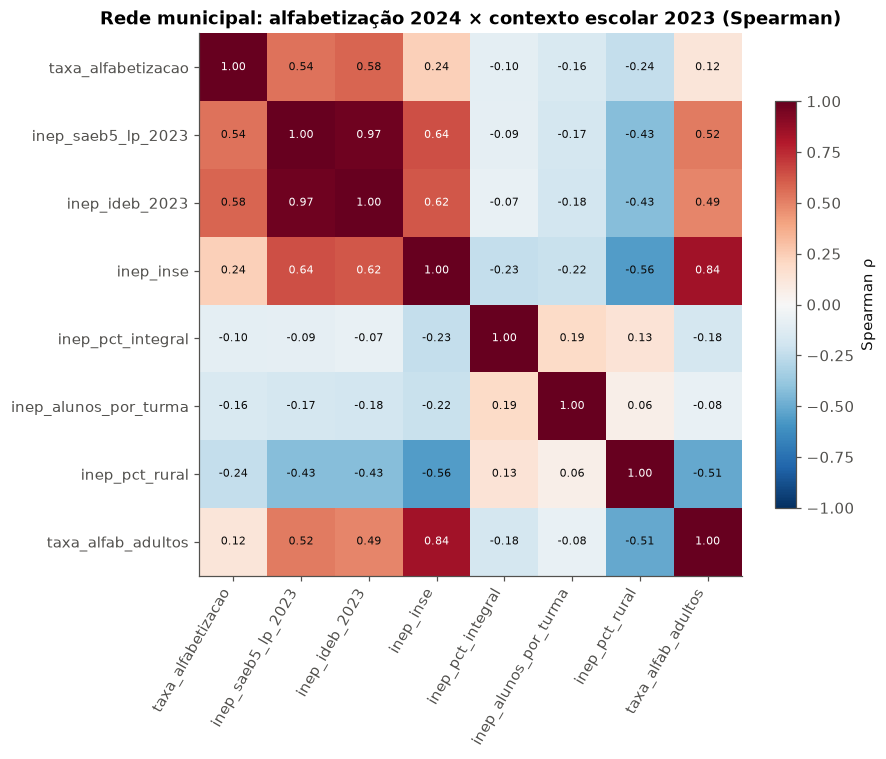

In [19]:
from src.preprocessing.base_analitica import contexto_escolar_rede

contexto = contexto_escolar_rede(escolas)
municipal_ctx = municipal_2024.merge(contexto[contexto["rede"] == C.REDE_MUNICIPAL].drop(columns="rede"),
                                     on="id_municipio").merge(ibge, on="id_municipio")
variaveis_ctx = ["taxa_alfabetizacao", "inep_saeb5_lp_2023", "inep_ideb_2023", "inep_inse",
                 "inep_pct_integral", "inep_alunos_por_turma", "inep_pct_rural", "taxa_alfab_adultos"]
G.matriz_correlacao(municipal_ctx, variaveis_ctx, "eda_correlacao_contexto_escolar",
                    "Rede municipal: alfabetização 2024 × contexto escolar 2023 (Spearman)");

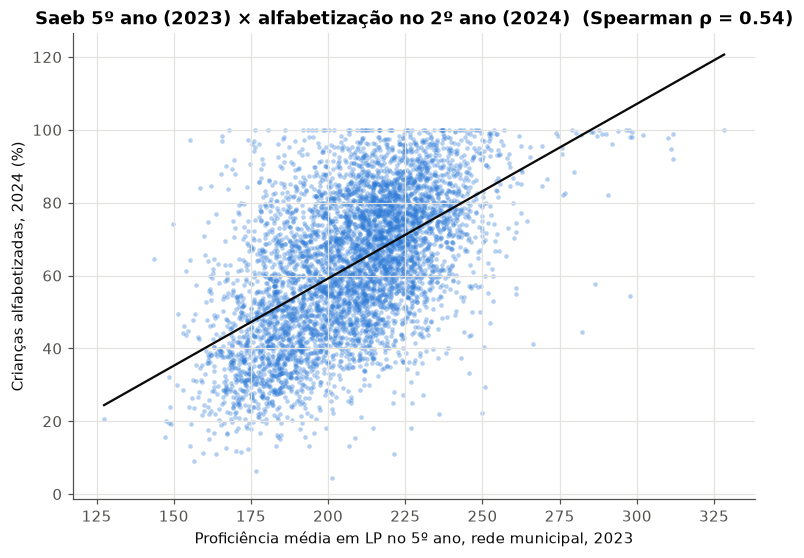

In [20]:
G.dispersao_relacao(municipal_ctx, "inep_saeb5_lp_2023", "taxa_alfabetizacao",
                    "Saeb 5º ano (2023) × alfabetização no 2º ano (2024)", "eda_saeb5_vs_alfabetizacao",
                    "Proficiência média em LP no 5º ano, rede municipal, 2023",
                    "Crianças alfabetizadas, 2024 (%)");

Valeu a pena. A nota do 5º ano das mesmas redes em 2023 acompanha a alfabetização do
2º ano em 2024 quase tanto quanto o próprio histórico (0,54 para o Saeb e 0,58 para o
Ideb, contra 0,63 da taxa de 2023). No fundo, as duas medem a mesma coisa: a qualidade
da rede.

Já o Inse, que mede o nível socioeconômico dos alunos da própria escola, conta a mesma
história do IBGE: no Brasil todo tem alguma relação com o resultado, mas dentro das
regiões ela some ou fica negativa. Ou seja, mesmo medida na escola, a renda não
determina se a criança vai se alfabetizar.

Redes com mais escolas rurais e turmas maiores alfabetizam um pouco menos, e redes com
mais bibliotecas, um pouco mais. Tempo integral quase não faz diferença.

Esses dados entram no modelo. Como continuam sendo informação por município, o ganho
deve ser pequeno por aluno e maior quando olharmos os municípios.

## 8. Metas

Municípios com meta em 2024: 5,232
Atingiram a meta            : 53.3%


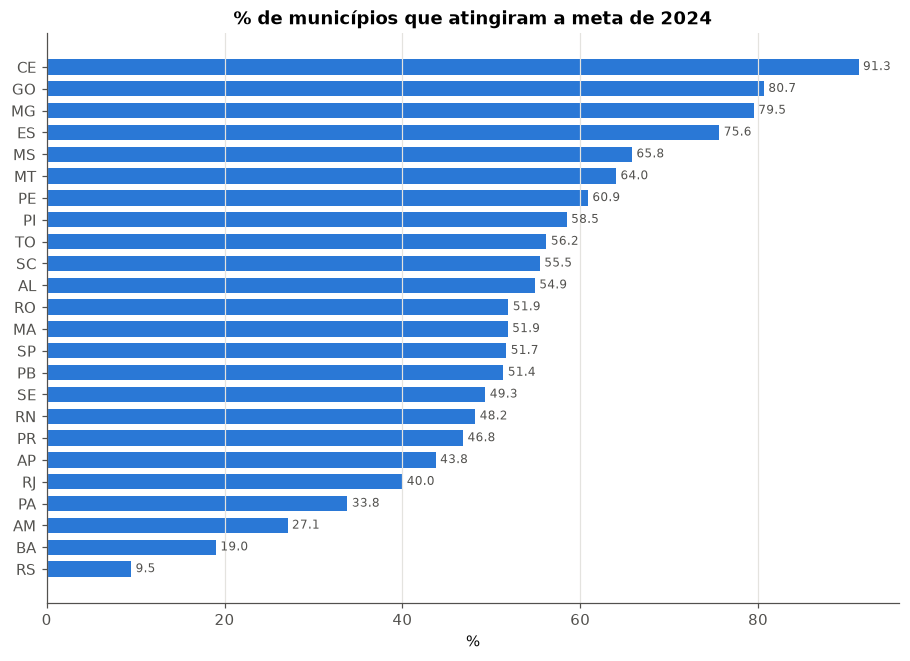

In [21]:
metas_2024 = municipal_2024.dropna(subset=["meta_taxa_ano"])
atingiu = (metas_2024["taxa_alfabetizacao"] >= metas_2024["meta_taxa_ano"])
print(f"Municípios com meta em {C.ANO_ALVO}: {len(metas_2024):,}")
print(f"Atingiram a meta            : {atingiu.mean():.1%}")
pct_uf = metas_2024.assign(atingiu=atingiu).groupby("sigla_uf")["atingiu"].mean().mul(100).reset_index()
G.taxa_por_categoria(pct_uf, "sigla_uf", "atingiu",
                     f"% de municípios que atingiram a meta de {C.ANO_ALVO}", "eda_meta_por_uf");

In [22]:
anterior = indicador[(indicador["ano"] == C.ANO_BASE) & (indicador["rede"] == C.REDE_MUNICIPAL)]
regra = metas_2024.merge(anterior[["id_municipio", "taxa_alfabetizacao"]], on="id_municipio",
                         suffixes=("", "_ant"))
previsao_ingenua = regra["taxa_alfabetizacao_ant"] < regra["meta_taxa_ano"]
real = regra["taxa_alfabetizacao"] < regra["meta_taxa_ano"]
print(f"Regra ingênua 'abaixo da meta em {C.ANO_BASE} → abaixo em {C.ANO_ALVO}': acerto de {(previsao_ingenua == real).mean():.1%}")

Regra ingênua 'abaixo da meta em 2023 → abaixo em 2024': acerto de 48.5%


Quase metade dos municípios ficou abaixo da meta de 2024. E a regra mais óbvia, "quem
estava abaixo vai continuar abaixo", acerta menos que jogar uma moeda. Isso vem da
regressão à média e de as metas terem sido calculadas a partir do próprio resultado de
2023. Para prever quem não vai bater a meta, precisamos de um modelo (notebook 04).

## 9. Resumo: hipóteses e o que entra no modelo

| # | Hipótese | O que vimos | Como usamos |
|---|---|---|---|
| H1 | O histórico do município é o que mais ajuda a prever | correlação de 0,64 entre os anos | taxas de 2023 por rede e da UF |
| H2 | O histórico da escola ajuda a prever | não deu para testar: o código da escola muda a cada ano | só o tamanho da escola no ano entra no modelo |
| H3 | Existe regressão à média | os piores subiram 12 p.p., os melhores caíram 9 | o modelo aprende isso com os dados |
| H4 | A política do estado pesa mais que a renda | renda com relação fraca ou negativa | UF e mesorregião como variáveis |
| H5 | A participação na prova mostra uma rede organizada | correlação de 0,3 a 0,5 | participação de 2023 |
| H6 | Prever aluno por aluno tem limite | a escola explica só 17% | olhar também o resultado por município |
| H7 | O RS em 2024 foge do padrão | queda de 19 p.p. | conferir o erro por região |
| H8 | Os dados das escolas do Inep ajudam mais que a renda | 0,54 a 0,58, contra 0,11 do IBGE | variáveis `inep_` por município e rede |

Três cuidados para o modelo não "colar" a resposta:
1. nada que vem da prova de 2024 entra como variável (taxa, nota, gap da meta);
2. na validação, um município inteiro fica de um lado só (treino ou teste), porque os
   alunos de uma mesma cidade têm as mesmas informações de contexto;
3. o preenchimento de nulos e a transformação das variáveis são aprendidos só com os
   dados de treino, dentro do `Pipeline`.